In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read Data

In [2]:
df = pd.read_csv('House_Rent_Dataset.csv')

In [3]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [4]:
df.shape

(4746, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   str    
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   str    
 5   Area Type          4739 non-null   str    
 6   Area Locality      4746 non-null   str    
 7   City               4746 non-null   str    
 8   Furnishing Status  4746 non-null   str    
 9   Tenant Preferred   4746 non-null   str    
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 882.1 KB


In [6]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [7]:
df.drop(['Posted On'],axis =1 ,inplace=True)

# Check null value

In [8]:
df.isnull().sum().sort_values()

BHK                  0
Floor                0
City                 0
Area Locality        0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
Bathroom             4
Rent                 5
Area Type            7
Size                 8
dtype: int64

<Axes: >

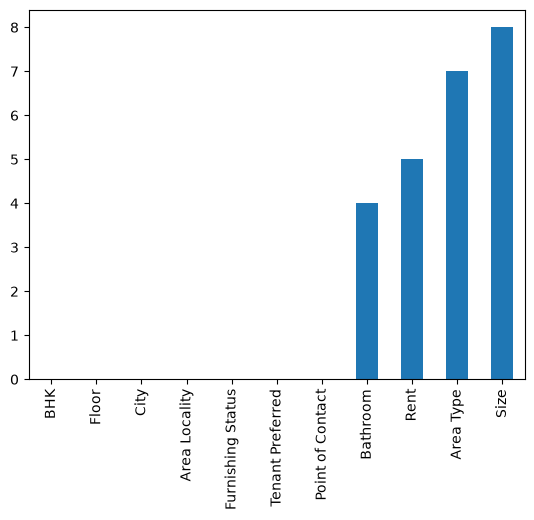

In [9]:
df.isnull().sum().sort_values().plot(kind='bar')

In [10]:
df.shape

(4746, 11)

In [11]:
df.Bathroom.head()

0    2.0
1    1.0
2    1.0
3    1.0
4    1.0
Name: Bathroom, dtype: float64

In [12]:
df.Bathroom.unique()

array([ 2.,  1., nan,  3.,  5.,  4.,  6.,  7., 10.])

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BHK                4746 non-null   int64  
 1   Rent               4741 non-null   float64
 2   Size               4738 non-null   float64
 3   Floor              4746 non-null   str    
 4   Area Type          4739 non-null   str    
 5   Area Locality      4746 non-null   str    
 6   City               4746 non-null   str    
 7   Furnishing Status  4746 non-null   str    
 8   Tenant Preferred   4746 non-null   str    
 9   Bathroom           4742 non-null   float64
 10  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(7)
memory usage: 804.9 KB


In [14]:
from sklearn.impute import SimpleImputer


In [15]:
impute = SimpleImputer(missing_values=np.nan,
    strategy='median')

In [16]:
df['Bathroom'] = impute.fit_transform(df[['Bathroom']])

In [17]:
impute = SimpleImputer(missing_values=np.nan,
    strategy='mean')
df['Size'] = impute.fit_transform(df[['Size']])

In [18]:
df.isnull().sum()

BHK                  0
Rent                 5
Size                 0
Floor                0
Area Type            7
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [19]:
impute = SimpleImputer(missing_values=np.nan,
    strategy='most_frequent')
impute.fit(df[['Area Type']])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Area Type']
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[object](1,)",['Super Area']


In [20]:
df['Area Type'] =pd.DataFrame(impute.transform(df[['Area Type']]))

In [21]:
df.dropna(inplace=True)

In [22]:
df.isnull().sum().sort_values().sum()

np.int64(0)

In [23]:
df.duplicated().sum()

np.int64(8)

In [24]:
df.drop_duplicates(inplace = True)

In [25]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.000000,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,2,20000.0,967.936049,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,2,17000.0,1000.000000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,2,10000.0,967.936049,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,2,7500.0,850.000000,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [26]:
cols = list(df.nunique().sort_values().index[:7])
cols

['Furnishing Status',
 'Area Type',
 'Point of Contact',
 'Tenant Preferred',
 'BHK',
 'City',
 'Bathroom']

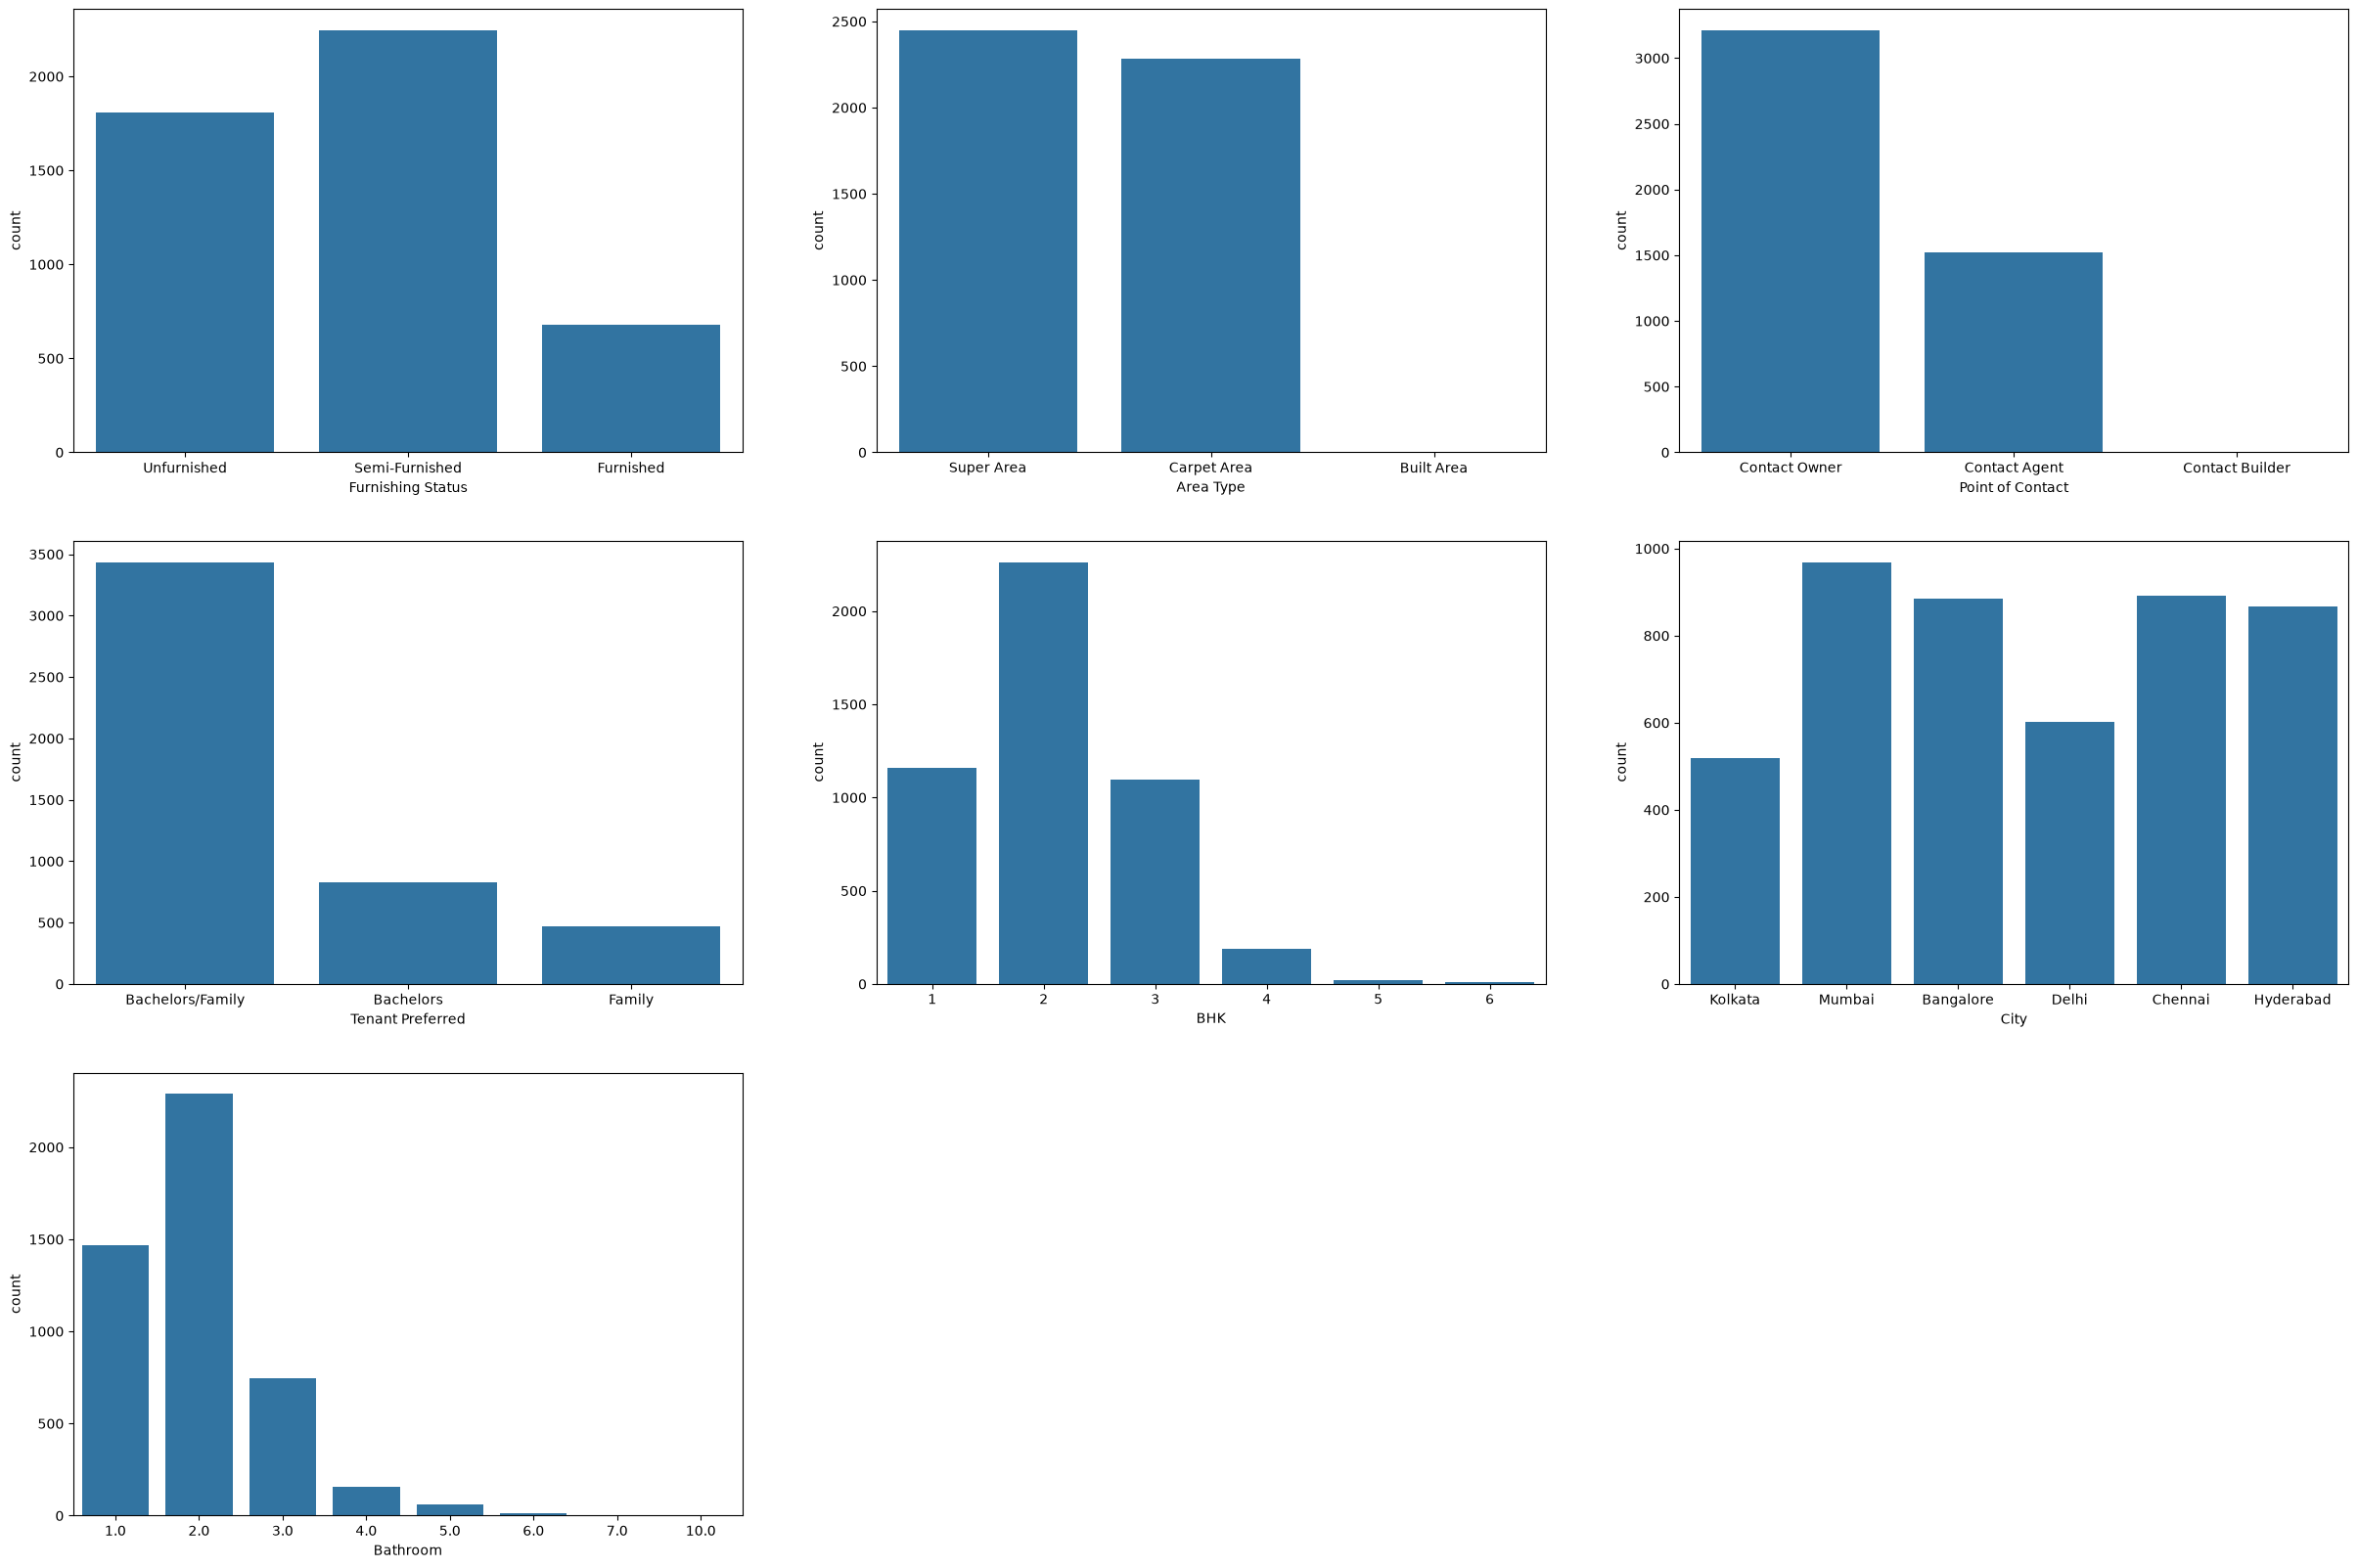

In [27]:
plt.figure(figsize=(30,20))
for n , col in enumerate(cols) :
    plt.subplot(3,3,n+1)
    sns.countplot(data=df,x=col)
    

In [28]:
cols

['Furnishing Status',
 'Area Type',
 'Point of Contact',
 'Tenant Preferred',
 'BHK',
 'City',
 'Bathroom']

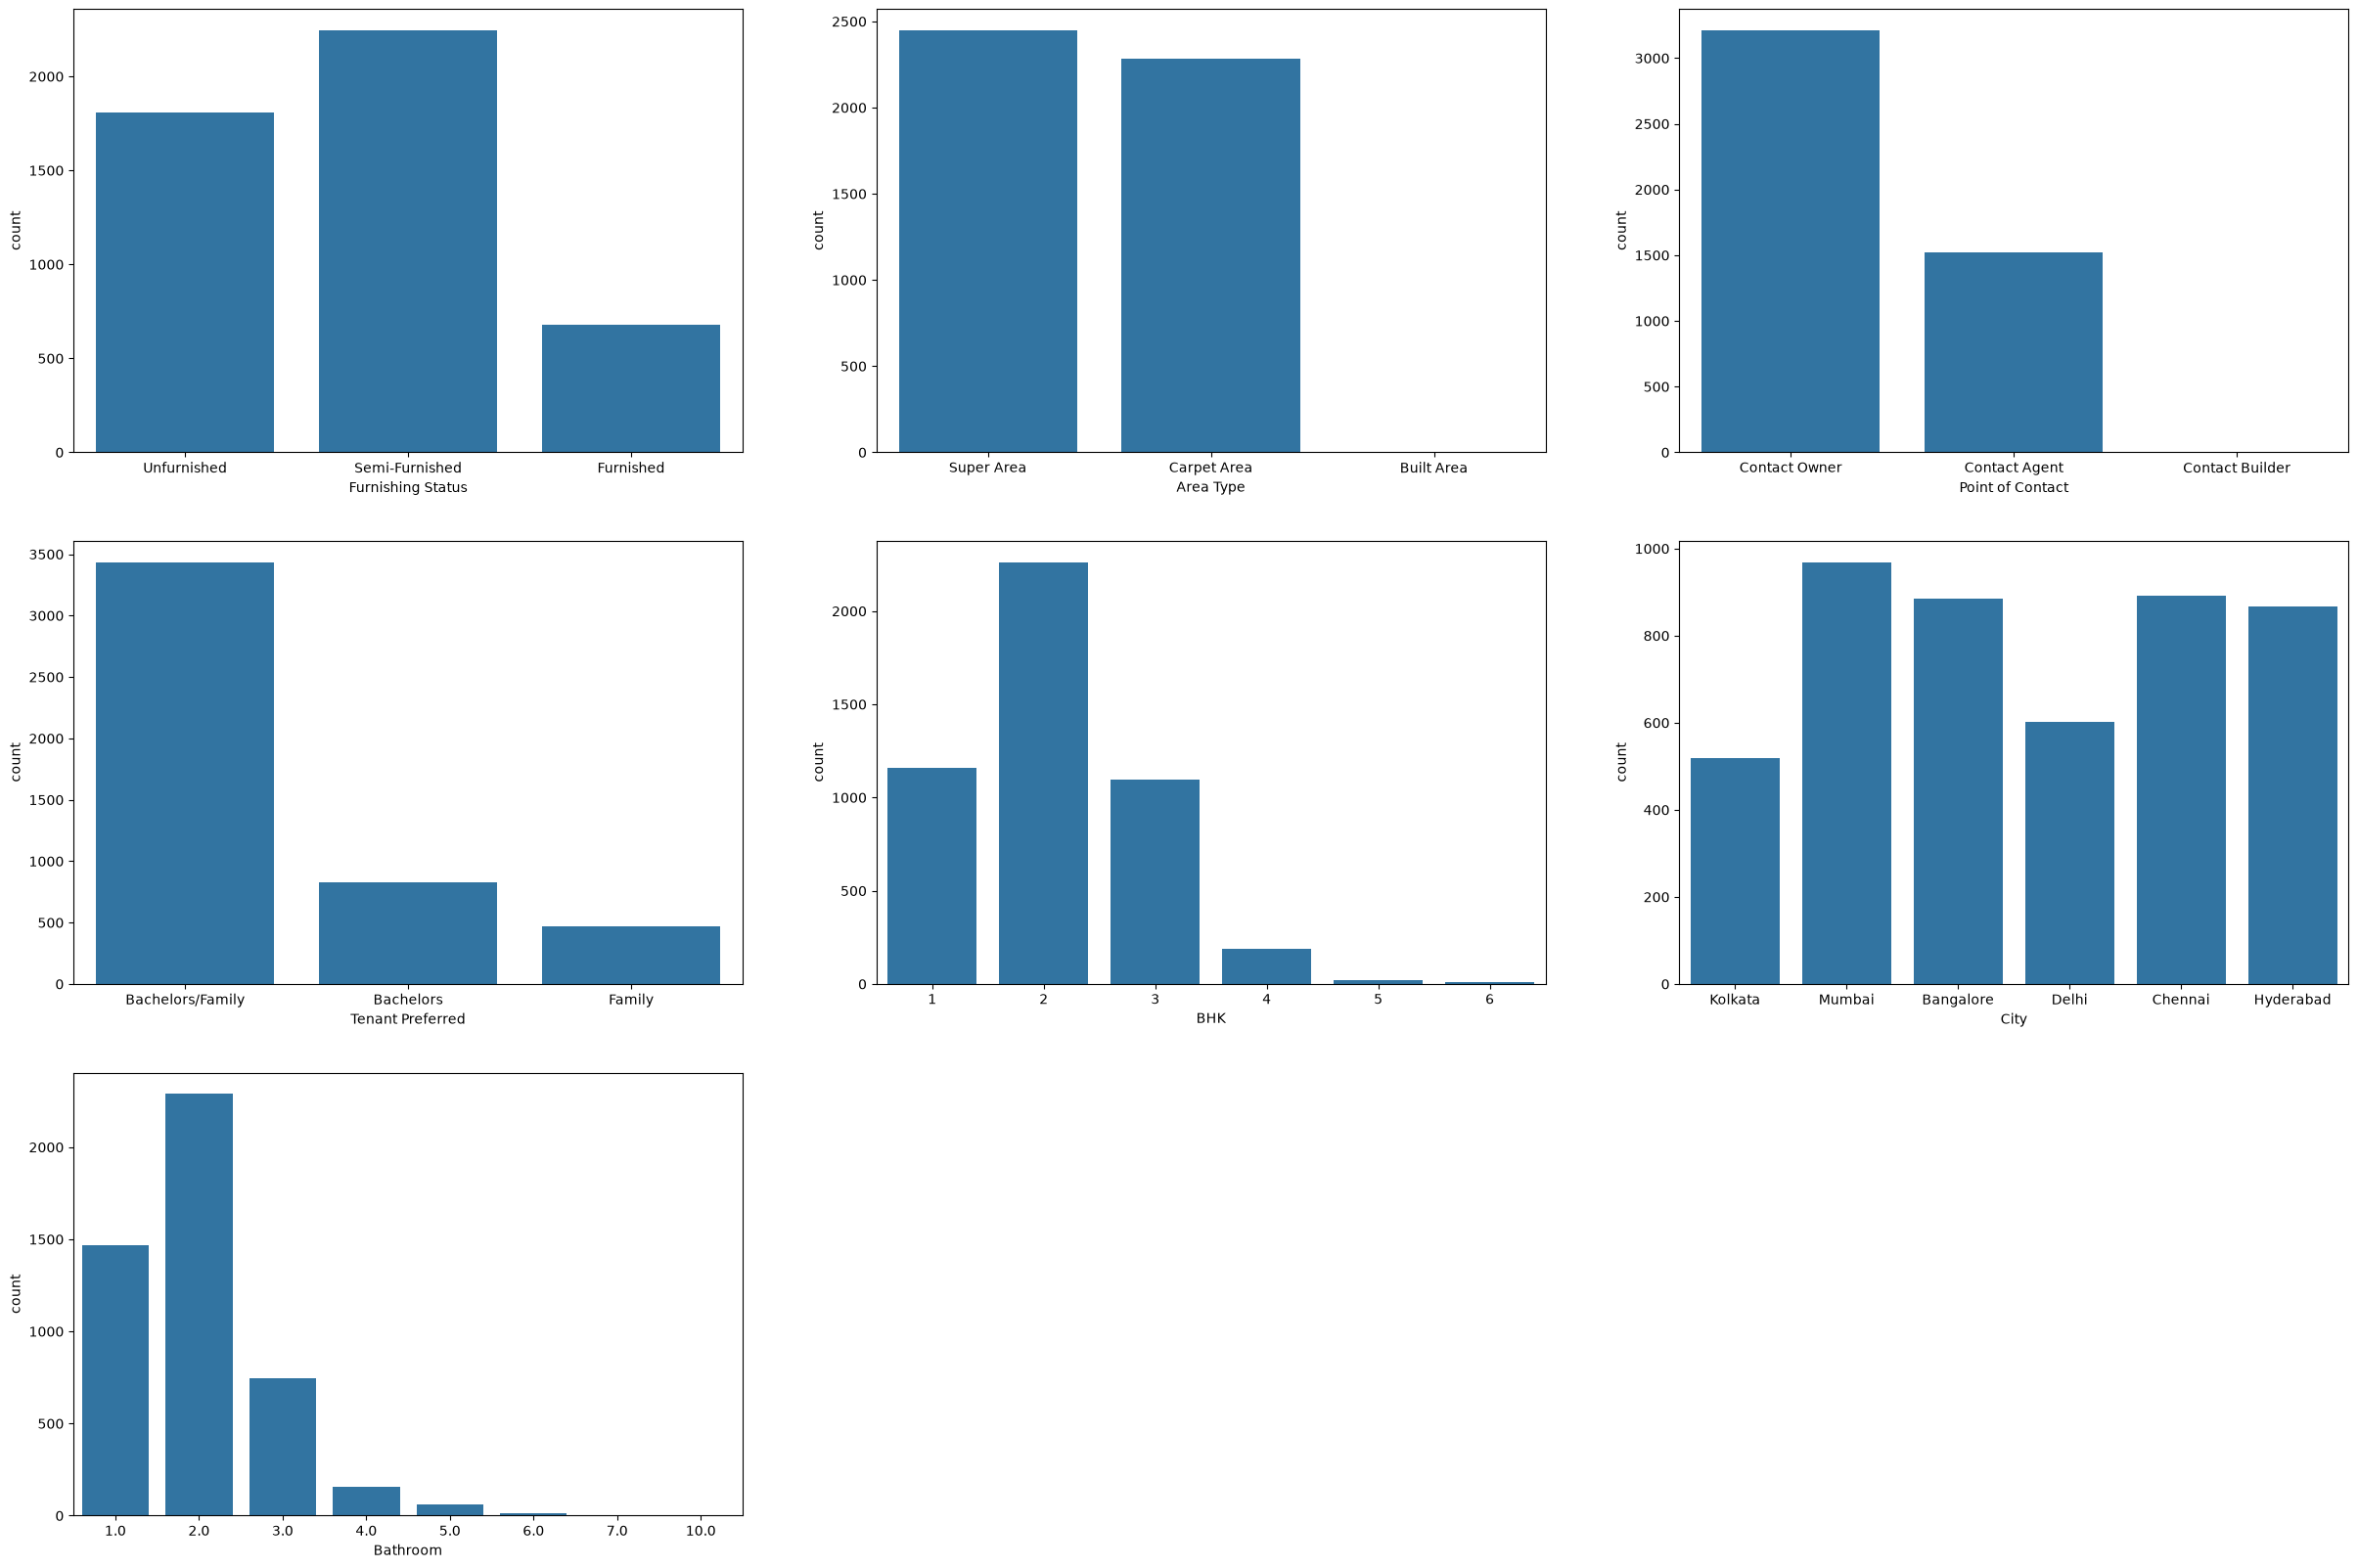

In [29]:
plt.figure(figsize=(30,20))

for n , k in enumerate(cols) :
    plt.subplot(3,3,n+1)
    sns.countplot(data=df,x=k)
    #plt.show()
    

In [30]:
"""
for col in cols :
    plt.figure(figsize=(30,20))
    print(col)
    for n , k in enumerate(cols) :
        plt.subplot(3,3,n+1)
        sns.countplot(data=df,x=col,hue=k)
    plt.show()
    """

'\nfor col in cols :\n    plt.figure(figsize=(30,20))\n    print(col)\n    for n , k in enumerate(cols) :\n        plt.subplot(3,3,n+1)\n        sns.countplot(data=df,x=col,hue=k)\n    plt.show()\n    '

<Axes: xlabel='Area Type', ylabel='count'>

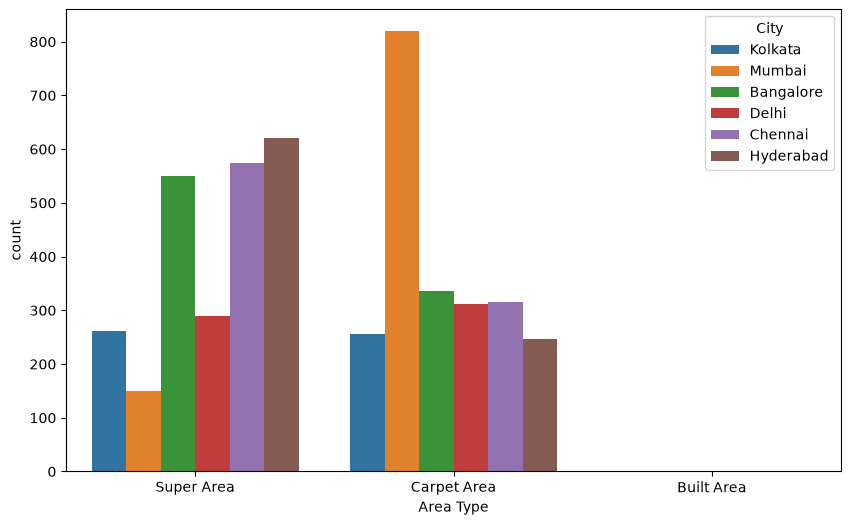

In [31]:
plt.figure(figsize=(10,6))
sns.countplot(data=df,x='Area Type',hue='City')

In [32]:
df.columns

Index(['BHK', 'Rent', 'Size', 'Floor', 'Area Type', 'Area Locality', 'City',
       'Furnishing Status', 'Tenant Preferred', 'Bathroom',
       'Point of Contact'],
      dtype='str')

<Axes: xlabel='BHK', ylabel='count'>

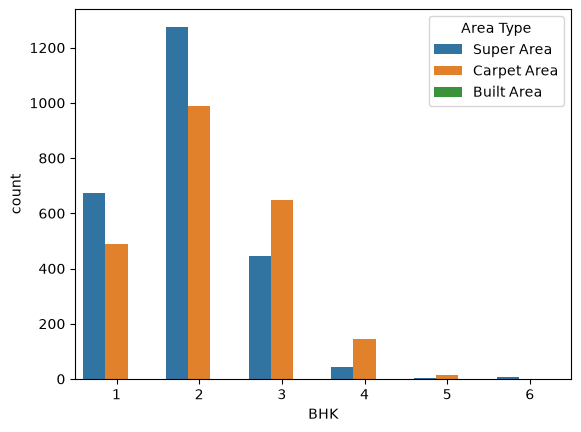

In [33]:
sns.countplot(data=df,x='BHK',hue='Area Type')

In [34]:
df['Bathroom'] = df['Bathroom'].astype(str)

<Axes: xlabel='BHK', ylabel='Size'>

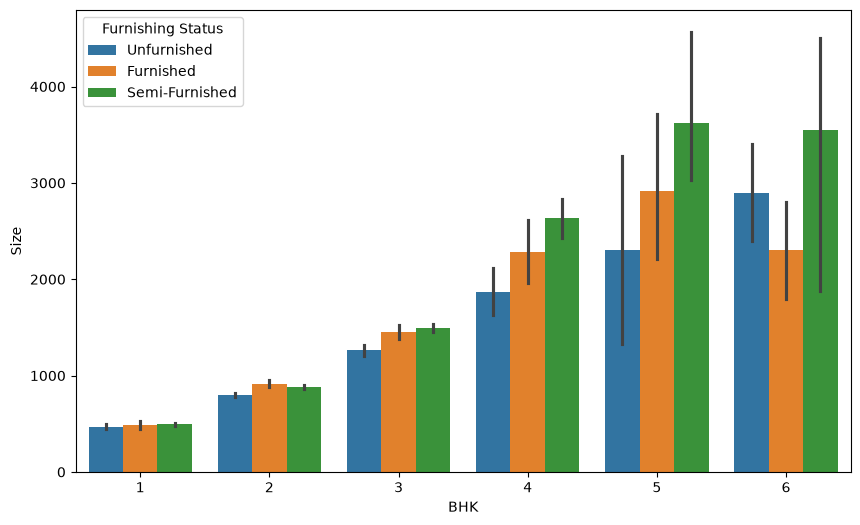

In [35]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x ='BHK',y='Size',hue='Furnishing Status')

<Axes: xlabel='BHK', ylabel='Rent'>

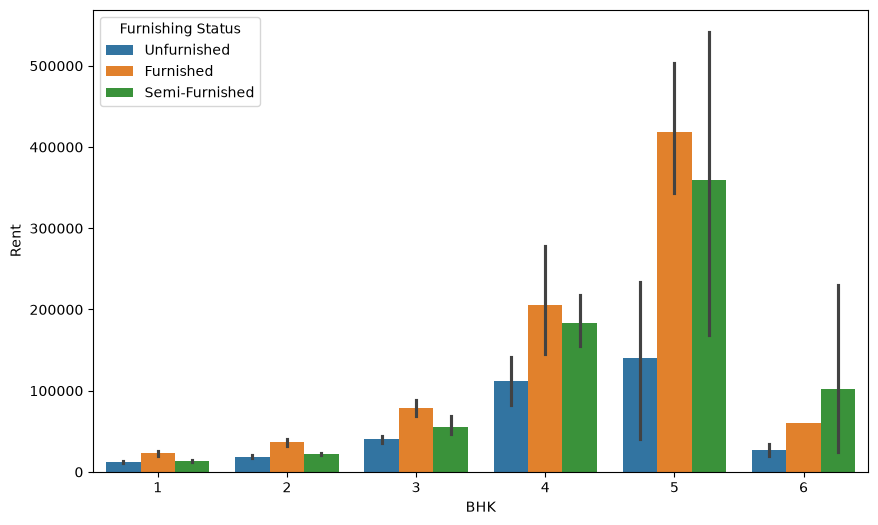

In [36]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x ='BHK',y='Rent',hue='Furnishing Status')

<Axes: xlabel='Bathroom', ylabel='BHK'>

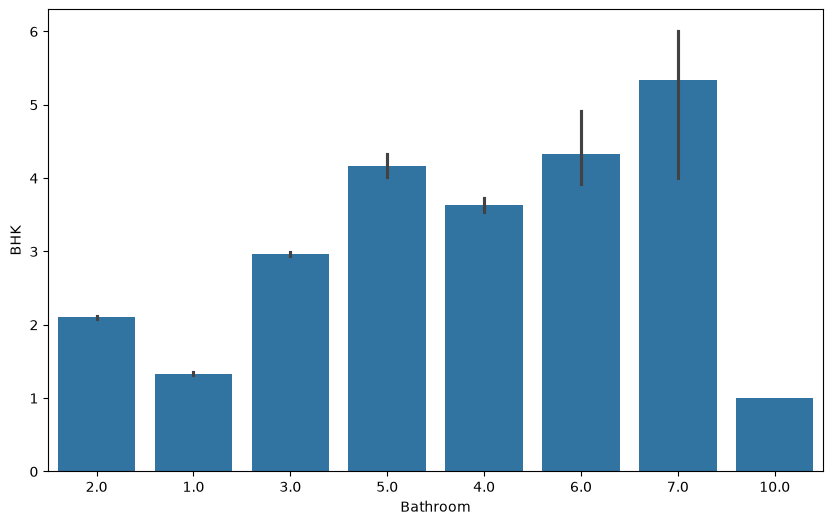

In [37]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x ='Bathroom',y='BHK',)

<Axes: xlabel='BHK', ylabel='Size'>

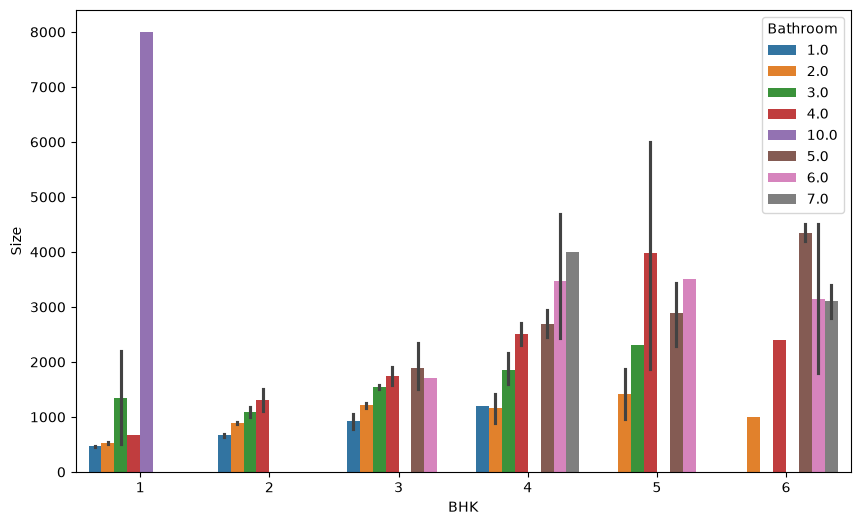

In [38]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x ='BHK',y='Size',hue='Bathroom')

<Axes: xlabel='Size', ylabel='Count'>

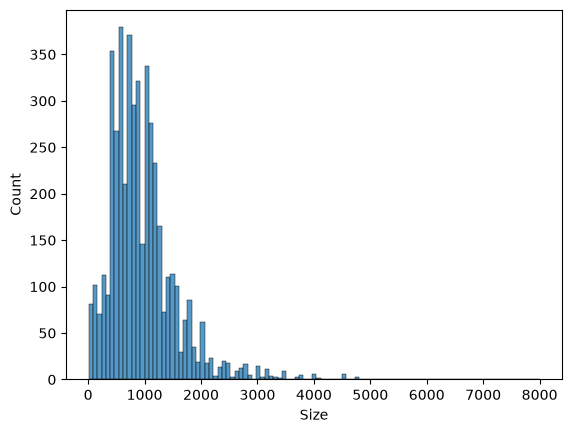

In [39]:
sns.histplot(data=df,x='Size')

<Axes: xlabel='Rent', ylabel='Count'>

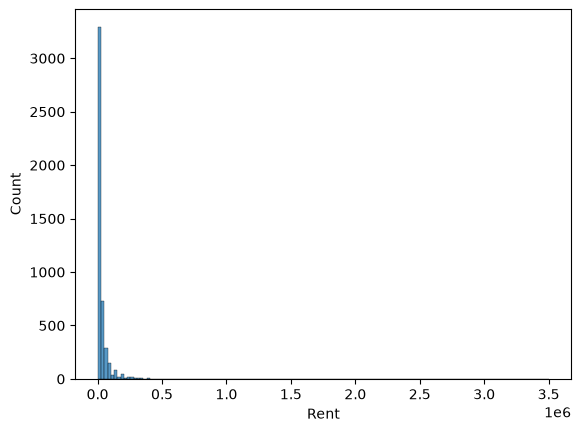

In [40]:
sns.histplot(data=df,x='Rent')

<Axes: xlabel='Size', ylabel='Rent'>

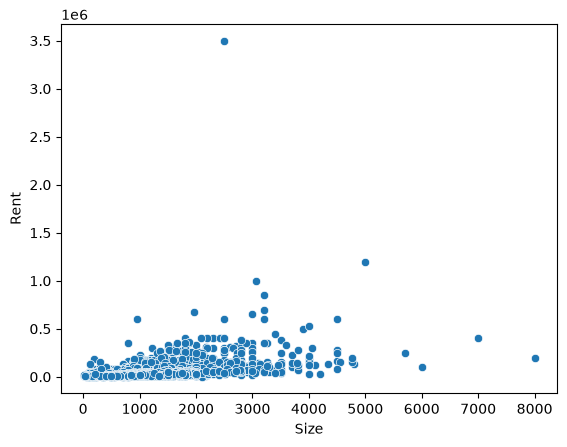

In [41]:
sns.scatterplot(data=df,x='Size',y='Rent')

<Axes: xlabel='Size', ylabel='Rent'>

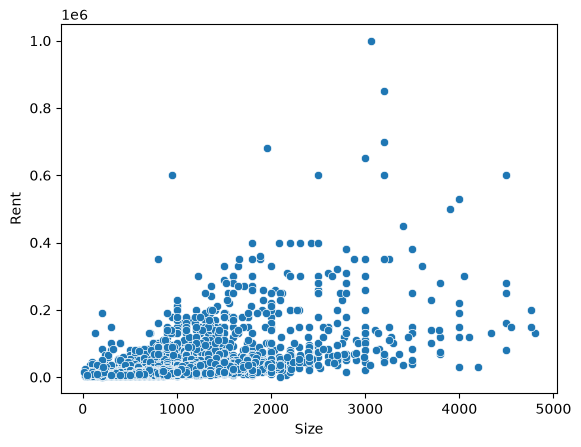

In [42]:
sns.scatterplot(data=df,x=df[df['Size']<5000]['Size'],y=df[df['Rent']<1500000]['Rent'])

<Axes: >

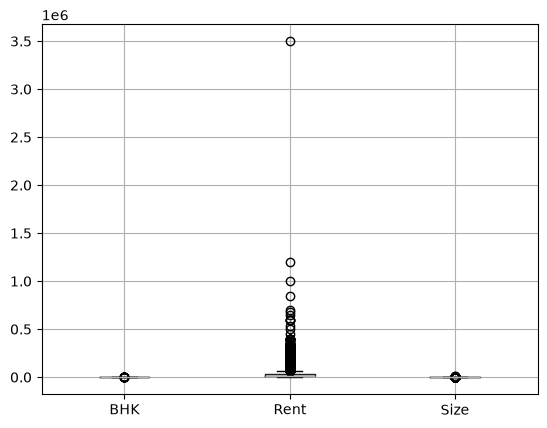

In [43]:
df.boxplot()

In [44]:
df=df[df['Size']<5000]
df=df[df['Rent']<1500000]

In [45]:
df.shape

(4727, 11)

In [46]:
df['Bathroom'] = df['Bathroom'].astype(float)

In [47]:
df.info()

<class 'pandas.DataFrame'>
Index: 4727 entries, 0 to 4745
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BHK                4727 non-null   int64  
 1   Rent               4727 non-null   float64
 2   Size               4727 non-null   float64
 3   Floor              4727 non-null   str    
 4   Area Type          4727 non-null   str    
 5   Area Locality      4727 non-null   str    
 6   City               4727 non-null   str    
 7   Furnishing Status  4727 non-null   str    
 8   Tenant Preferred   4727 non-null   str    
 9   Bathroom           4727 non-null   float64
 10  Point of Contact   4727 non-null   str    
dtypes: float64(3), int64(1), str(7)
memory usage: 842.0 KB


# Encoding

In [48]:
cols=df.select_dtypes('object')

C:\Users\abdoa\AppData\Local\Temp\ipykernel_11180\176693104.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols=df.select_dtypes('object')


In [49]:
cols.info()

<class 'pandas.DataFrame'>
Index: 4727 entries, 0 to 4745
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Floor              4727 non-null   str  
 1   Area Type          4727 non-null   str  
 2   Area Locality      4727 non-null   str  
 3   City               4727 non-null   str  
 4   Furnishing Status  4727 non-null   str  
 5   Tenant Preferred   4727 non-null   str  
 6   Point of Contact   4727 non-null   str  
dtypes: str(7)
memory usage: 694.3 KB


In [50]:
cols.nunique()

Floor                 479
Area Type               3
Area Locality        2233
City                    6
Furnishing Status       3
Tenant Preferred        3
Point of Contact        3
dtype: int64

In [51]:
df

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.000000,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,2,20000.0,967.936049,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,2,17000.0,1000.000000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,2,10000.0,967.936049,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,2,7500.0,850.000000,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...
4741,2,15000.0,1000.000000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner
4742,3,29000.0,2000.000000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner
4743,3,35000.0,1750.000000,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent
4744,3,45000.0,1500.000000,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent


In [52]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [53]:
for c in ['Floor','Area Locality','City']:
    lb = LabelEncoder()
    df[c] = lb.fit_transform(df[c])


In [54]:
df.info()

<class 'pandas.DataFrame'>
Index: 4727 entries, 0 to 4745
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BHK                4727 non-null   int64  
 1   Rent               4727 non-null   float64
 2   Size               4727 non-null   float64
 3   Floor              4727 non-null   int64  
 4   Area Type          4727 non-null   str    
 5   Area Locality      4727 non-null   int64  
 6   City               4727 non-null   int64  
 7   Furnishing Status  4727 non-null   str    
 8   Tenant Preferred   4727 non-null   str    
 9   Bathroom           4727 non-null   float64
 10  Point of Contact   4727 non-null   str    
dtypes: float64(3), int64(4), str(4)
memory usage: 673.5 KB


In [55]:
cols=df.select_dtypes('object')
type(cols)

C:\Users\abdoa\AppData\Local\Temp\ipykernel_11180\3323818227.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols=df.select_dtypes('object')


pandas.DataFrame

In [56]:
cols.columns

Index(['Area Type', 'Furnishing Status', 'Tenant Preferred',
       'Point of Contact'],
      dtype='str')

In [57]:
'N_'+str(len(df.columns))

'N_11'

In [58]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.000000,454,Super Area,220,4,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,2,20000.0,967.936049,14,Super Area,1525,4,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,2,17000.0,1000.000000,14,Super Area,1758,4,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,2,10000.0,967.936049,10,Super Area,525,4,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,2,7500.0,850.000000,10,Carpet Area,1888,4,Unfurnished,Bachelors,1.0,Contact Owner


In [59]:
for c in list(cols.columns) :
    print(c)   
    onehotencoder=OneHotEncoder()
    swap = onehotencoder.fit_transform(np.array(df[c]).reshape(-1,1)).toarray()
    for i in range(swap.shape[1]):
        df['N_'+str(len(df.columns))] = swap[:,i]

Area Type
Furnishing Status
Tenant Preferred
Point of Contact


In [60]:
df.drop(list(cols.columns),axis =1,inplace = True)

In [61]:
df.head()

,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,N_11,N_12,N_13,N_14,N_15,N_16,N_17,N_18,N_19,N_20,N_21,N_22
0,2,10000.0,1100.000000,454,220,4,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,2,20000.0,967.936049,14,1525,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,17000.0,1000.000000,14,1758,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,2,10000.0,967.936049,10,525,4,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,7500.0,850.000000,10,1888,4,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [62]:
df.info()

<class 'pandas.DataFrame'>
Index: 4727 entries, 0 to 4745
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BHK            4727 non-null   int64  
 1   Rent           4727 non-null   float64
 2   Size           4727 non-null   float64
 3   Floor          4727 non-null   int64  
 4   Area Locality  4727 non-null   int64  
 5   City           4727 non-null   int64  
 6   Bathroom       4727 non-null   float64
 7   N_11           4727 non-null   float64
 8   N_12           4727 non-null   float64
 9   N_13           4727 non-null   float64
 10  N_14           4727 non-null   float64
 11  N_15           4727 non-null   float64
 12  N_16           4727 non-null   float64
 13  N_17           4727 non-null   float64
 14  N_18           4727 non-null   float64
 15  N_19           4727 non-null   float64
 16  N_20           4727 non-null   float64
 17  N_21           4727 non-null   float64
 18  N_22           4727 non-

In [63]:
X = df.drop(['Rent'],axis =1)

In [64]:
X.head()

,BHK,Size,Floor,Area Locality,City,Bathroom,N_11,N_12,N_13,N_14,N_15,N_16,N_17,N_18,N_19,N_20,N_21,N_22
0,2,1100.000000,454,220,4,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,2,967.936049,14,1525,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,1000.000000,14,1758,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,2,967.936049,10,525,4,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,850.000000,10,1888,4,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [65]:
y = df['Rent']

In [66]:
y.head()

0    10000.0
1    20000.0
2    17000.0
3    10000.0
4     7500.0
Name: Rent, dtype: float64

# Scaling

In [67]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler

In [68]:
scaler = RobustScaler() 
X_scaler = scaler.fit_transform(X)

In [69]:
X_scaler

array([[ 0.        ,  0.38610039,  0.73837209, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.18214062, -0.54069767, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.23166023, -0.54069767, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 1.        ,  1.38996139,  0.20348837, ...,  1.        ,
         0.        , -1.        ],
       [ 1.        ,  1.003861  ,  0.0755814 , ...,  1.        ,
         0.        , -1.        ],
       [ 0.        ,  0.23166023,  0.3255814 , ...,  0.        ,
         0.        ,  0.        ]], shape=(4727, 18))

# Split data

In [70]:
from sklearn.model_selection import train_test_split

In [71]:
X_train,X_test,y_train,y_test = train_test_split(X_scaler,y,test_size=0.2,shuffle=True,random_state=42)

In [72]:
X_train.shape ,y_train.shape

((3781, 18), (3781,))

In [73]:
X_test.shape ,y_test.shape

((946, 18), (946,))

# Linear Regression

In [74]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge

In [75]:
LR = LinearRegression()

In [76]:
LR.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](18,)","[ 229.31, 13927.31, -901.91,..., 11333.86, 21.05,-11354.92]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.338e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,18
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](18,)","[88.25,55.24,39.76,..., 0. , 0. , 0. ]"


In [77]:
LR.coef_

array([   229.31325979,  13927.31474765,   -901.90564367,  -2124.01281136,
        18982.74359288,  20451.02615502,  -3490.53636758,   5019.97767124,
        -1529.44130367,   7743.16357865,  -3102.57564146,  -4640.58793719,
        -3233.08558578,   5141.0048077 ,  -1907.91922193,  11333.86284648,
           21.05452518, -11354.91737166])

In [78]:
LR.coef_.shape

(18,)

In [79]:
LR.intercept_

np.float64(23382.58536805887)

In [80]:
LR.score(X_test,y_test)

0.5002964469938878

In [81]:
LR.score(X_train,y_train)

0.4509258938043458

In [82]:
from  sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score

In [83]:
y_pred = LR.predict(X_test)

In [84]:
print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("RMSE : ",root_mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  23042.11695764951
MSE :  1444428483.752289
RMSE :  38005.637525928825
R2 :  0.5002964469938878


In [85]:
from sklearn.linear_model import SGDRegressor

In [86]:
sgd = SGDRegressor(learning_rate='constant',max_iter=5000,eta0=0.01)

In [87]:
sgd.fit(X_train,y_train)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",5000
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'constant'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get th

In [88]:
sgd.score(X_test,y_test)

0.49489078022227595

In [89]:
y_pred = sgd.predict(X_test)

In [90]:
mean_absolute_error(y_test,y_pred)

23204.487476607672

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
#from catboost import CatBoostRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [92]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    #"CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [93]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/14 [00:00<?, ?it/s]

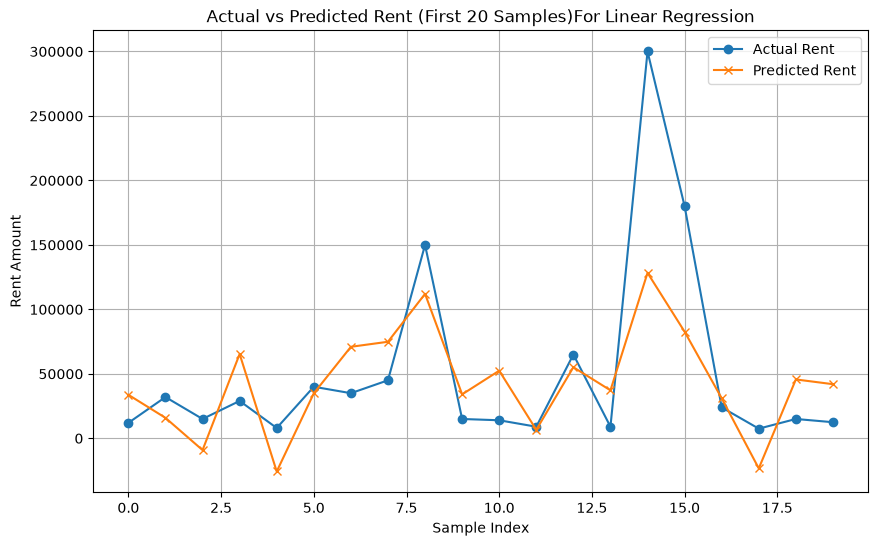

  7%|▋         | 1/14 [00:00<00:02,  5.39it/s]

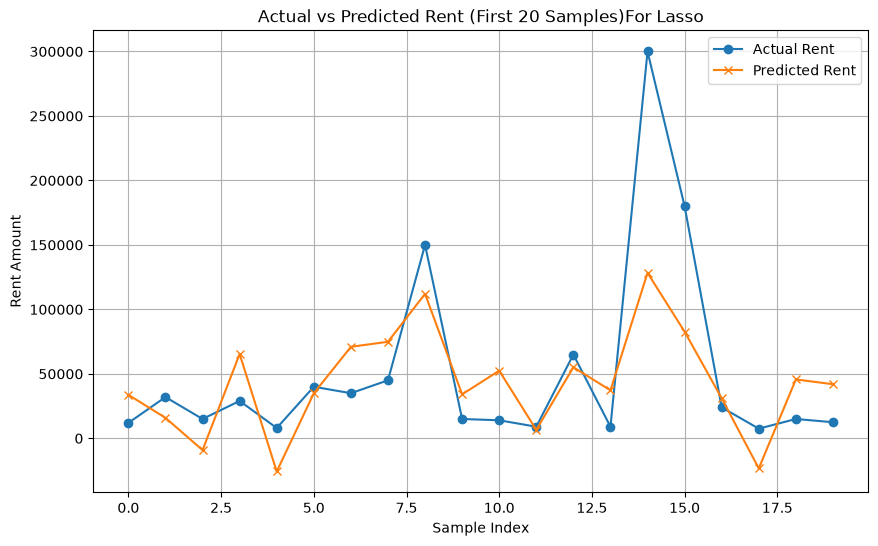

 14%|█▍        | 2/14 [00:00<00:02,  5.60it/s]

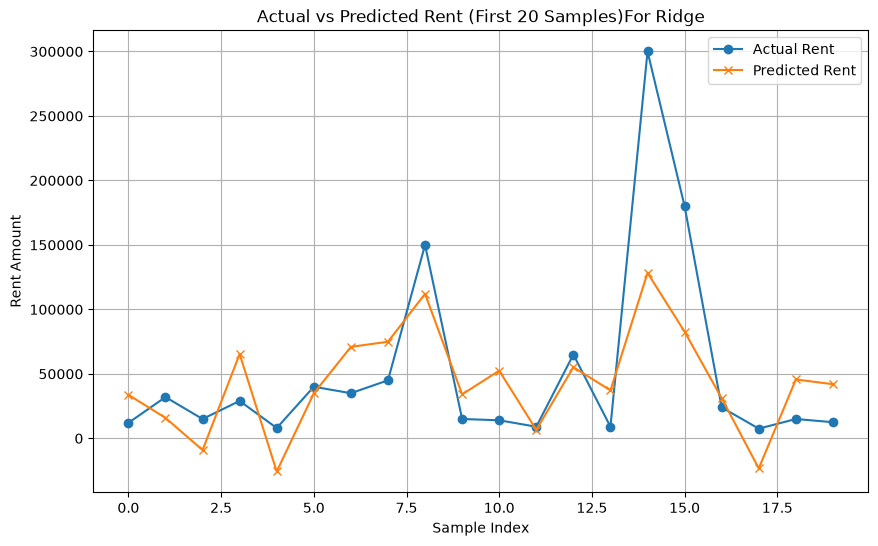

 21%|██▏       | 3/14 [00:00<00:02,  5.49it/s]

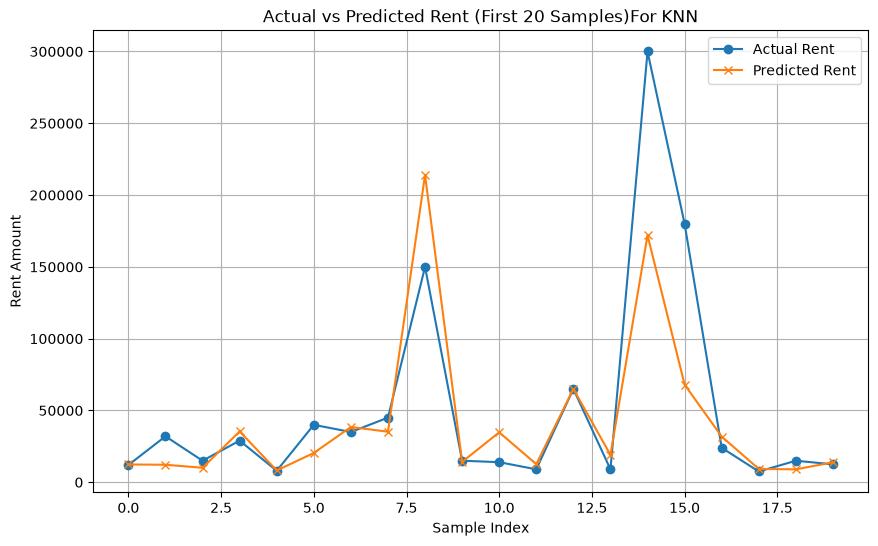

 29%|██▊       | 4/14 [00:00<00:02,  4.46it/s]

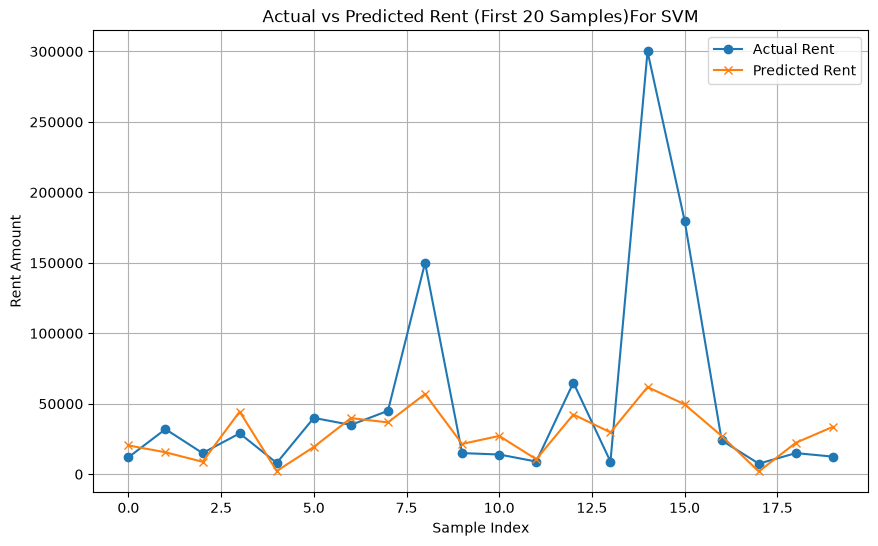

 36%|███▌      | 5/14 [00:01<00:03,  2.38it/s]

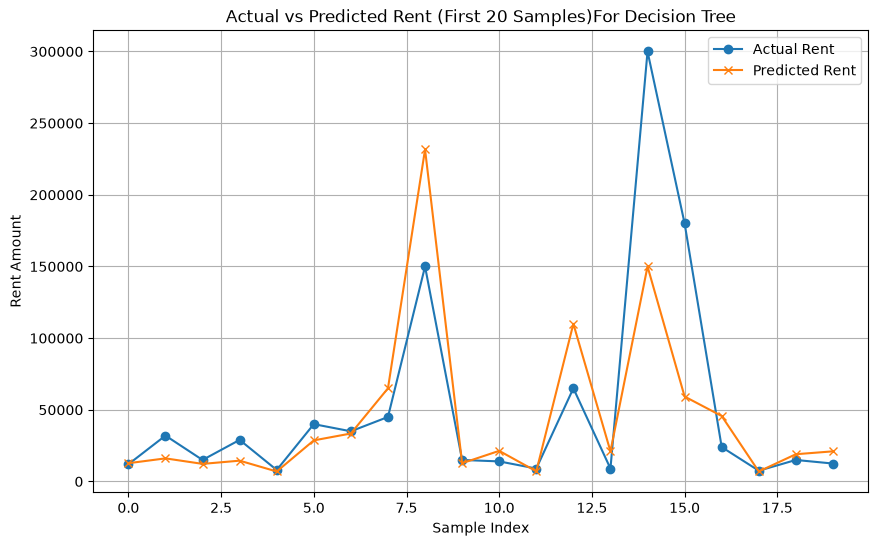

 43%|████▎     | 6/14 [00:01<00:02,  2.95it/s]

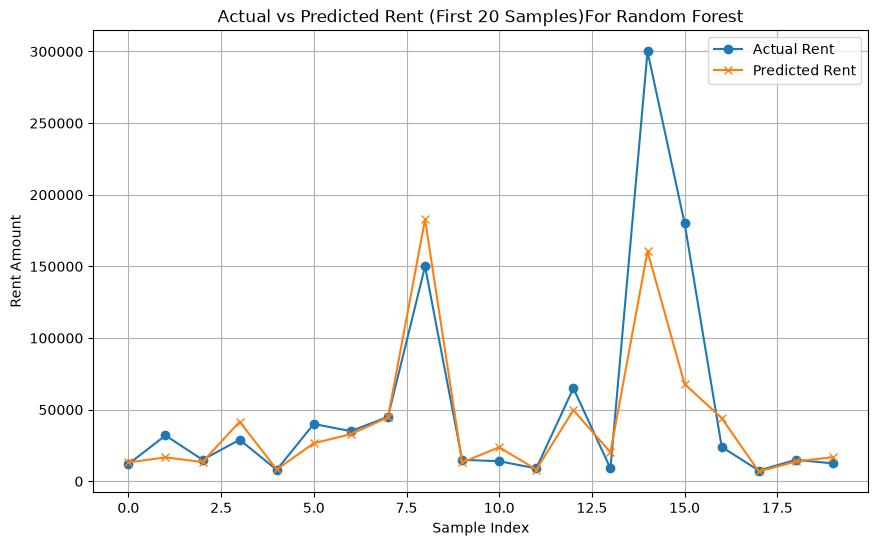

 50%|█████     | 7/14 [00:02<00:02,  2.35it/s]

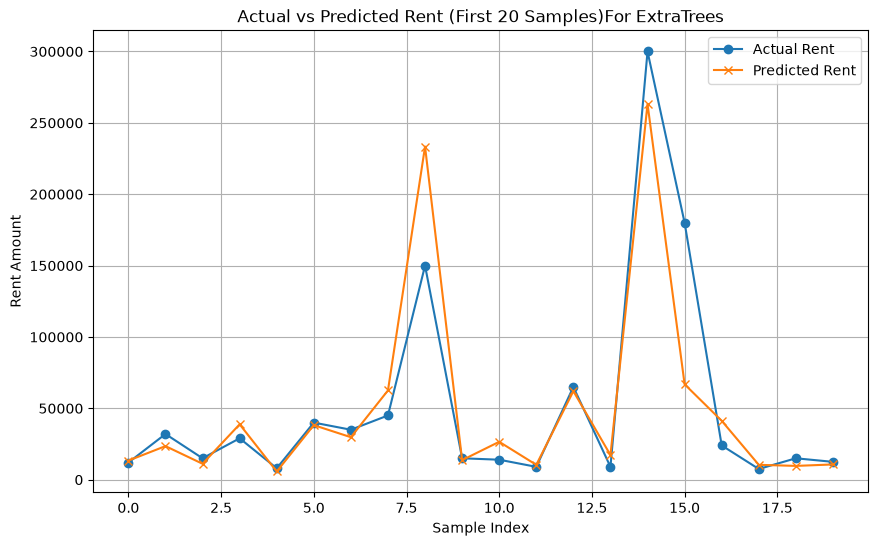

 57%|█████▋    | 8/14 [00:03<00:04,  1.38it/s]

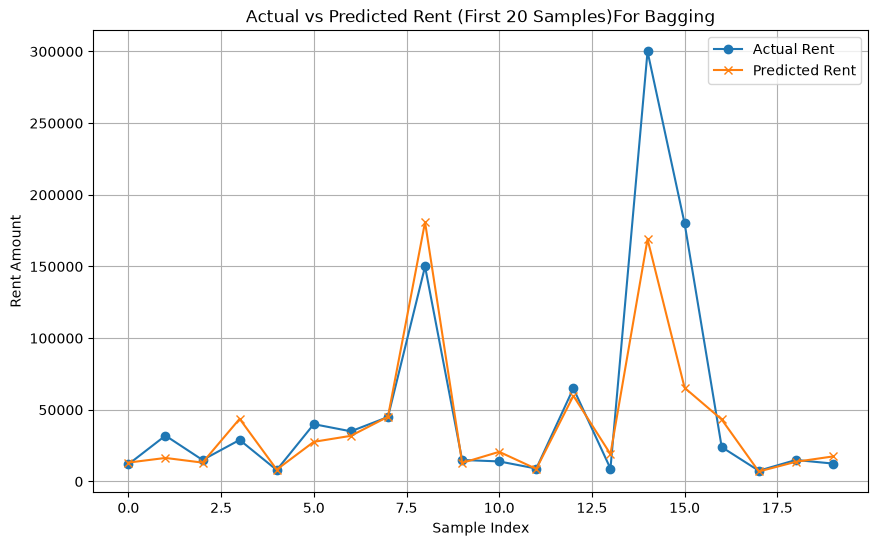

 64%|██████▍   | 9/14 [00:04<00:03,  1.42it/s]

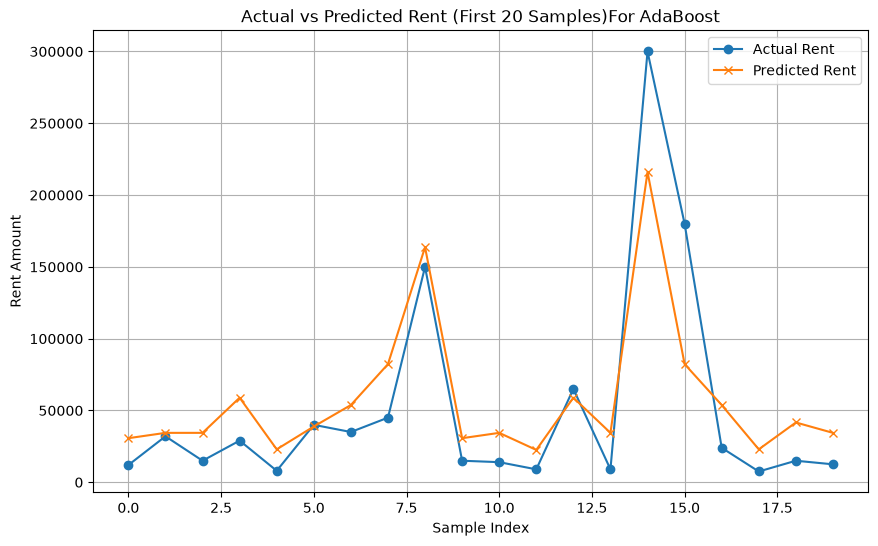

 71%|███████▏  | 10/14 [00:04<00:02,  1.78it/s]

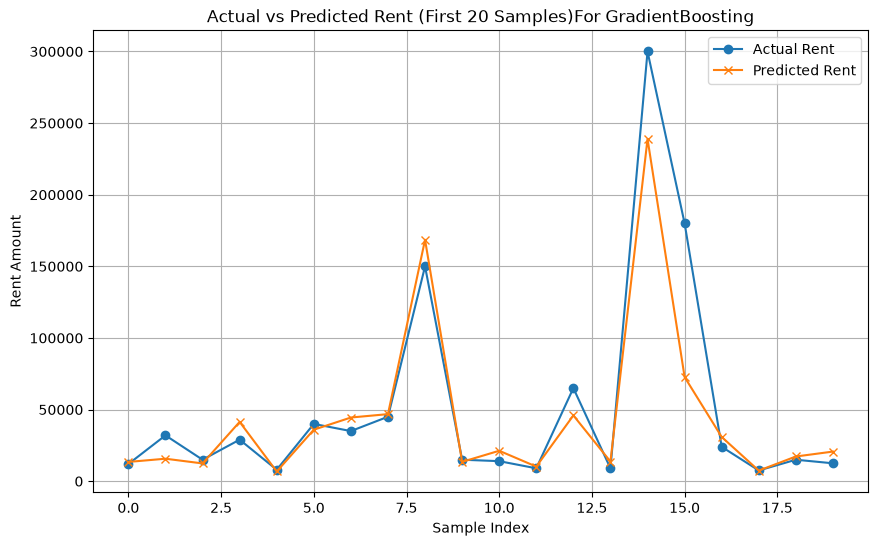

 79%|███████▊  | 11/14 [00:05<00:01,  1.75it/s]

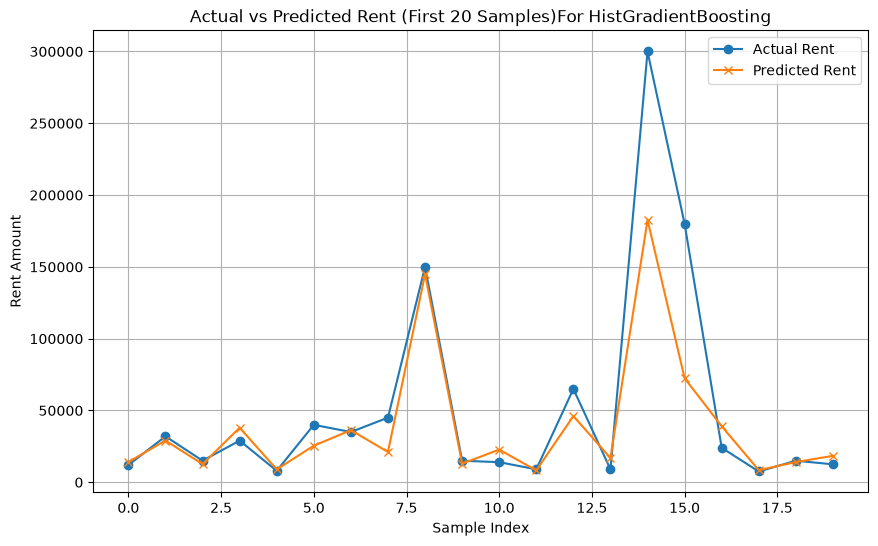

 86%|████████▌ | 12/14 [00:05<00:01,  1.85it/s]

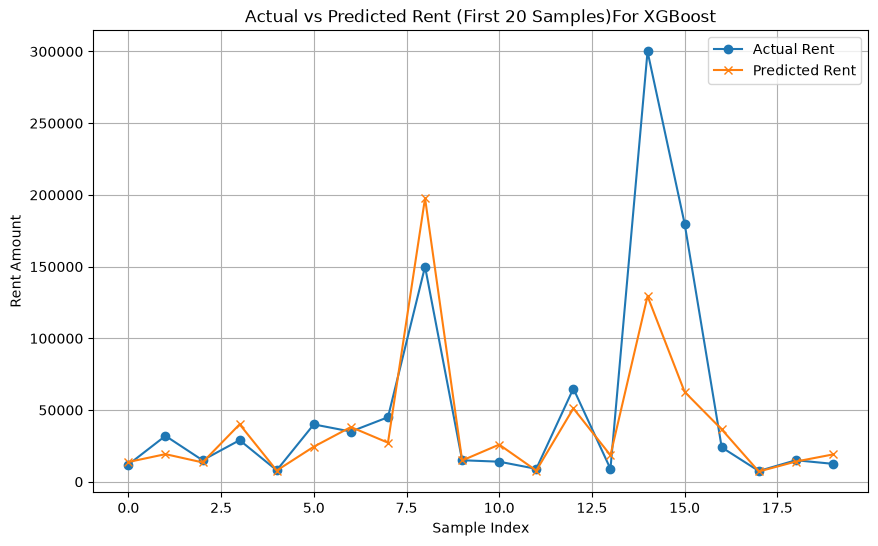

 93%|█████████▎| 13/14 [00:06<00:00,  2.04it/s]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000826 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 780
[LightGBM] [Info] Number of data points in the train set: 3781, number of used features: 16
[LightGBM] [Info] Start training from score 33914.203650


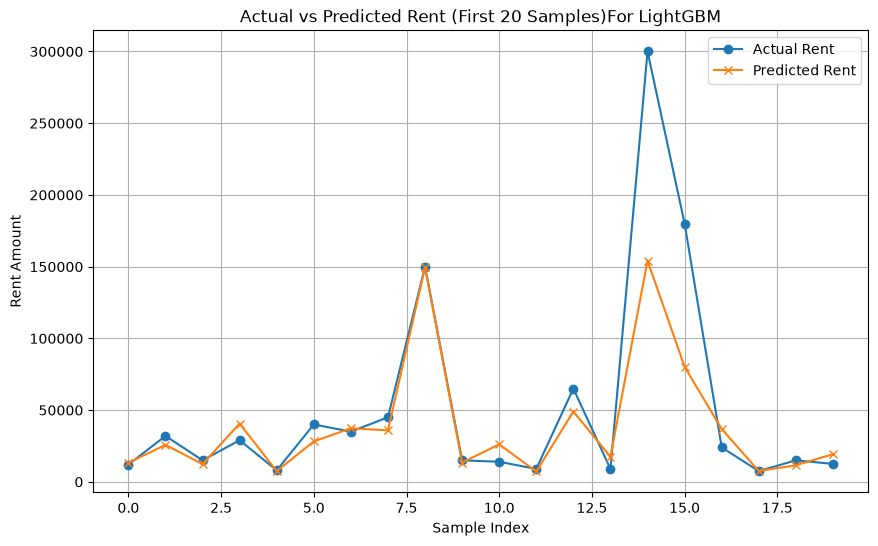

100%|██████████| 14/14 [00:06<00:00,  2.20it/s]


In [94]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [95]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [96]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    #('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [97]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [98]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
HistGradientBoosting,8242.600732,11612.601848,4.103930e+08,6.684314e+08,20258.159096,25854.039362,0.876799,0.768755
LightGBM,8079.081039,11750.876639,3.858950e+08,7.089101e+08,19644.210538,26625.366375,0.884153,0.754751
ExtraTrees,9.989421,11962.457368,2.046587e+04,8.880551e+08,143.058970,29800.252634,0.999994,0.692775
Simple Voting,8437.321582,11750.876639,2.804700e+08,7.089101e+08,16747.239861,26625.366375,0.915802,0.690384
Voting,8437.321582,11750.876639,2.804700e+08,7.089101e+08,16747.239861,26625.366375,0.915802,0.690384
GradientBoosting,9487.030580,11829.823337,4.229178e+08,9.112078e+08,20564.966064,30186.218800,0.873039,0.684765
Random Forest,6588.763050,11735.155185,1.852180e+08,9.184214e+08,13609.482687,30305.468033,0.944397,0.682270
Weighted Voting,9569.014068,11750.876639,3.430752e+08,7.089101e+08,18522.288505,26625.366375,0.897008,0.680330
Bagging,6580.721011,11645.962237,1.853278e+08,9.288664e+08,13613.513589,30477.309972,0.944364,0.678656
XGBoost,5708.246931,11645.771774,9.998393e+07,9.880680e+08,9999.196305,31433.548783,0.969985,0.658175


<Axes: >

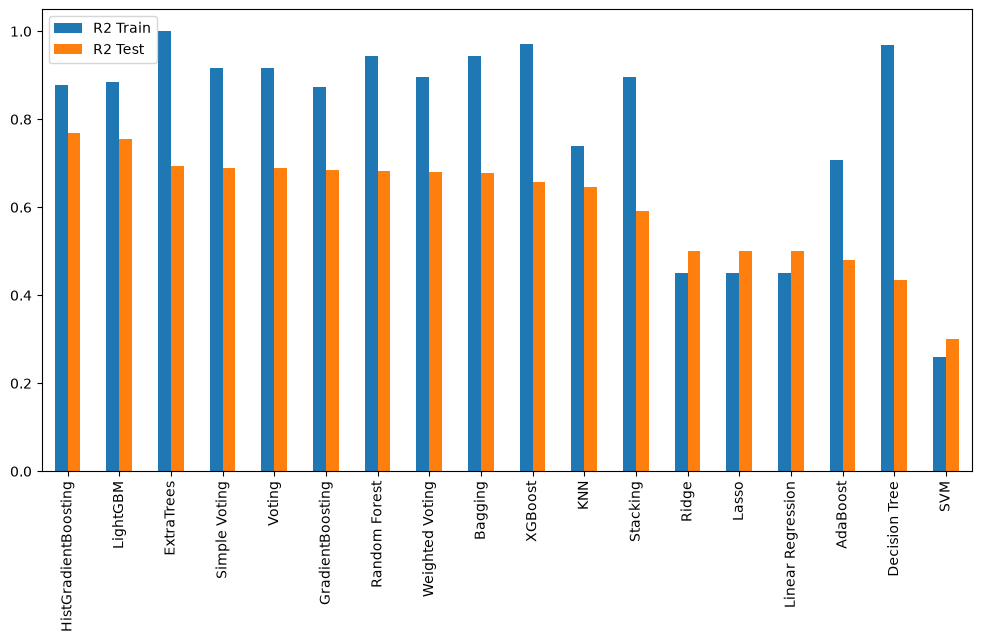

In [99]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

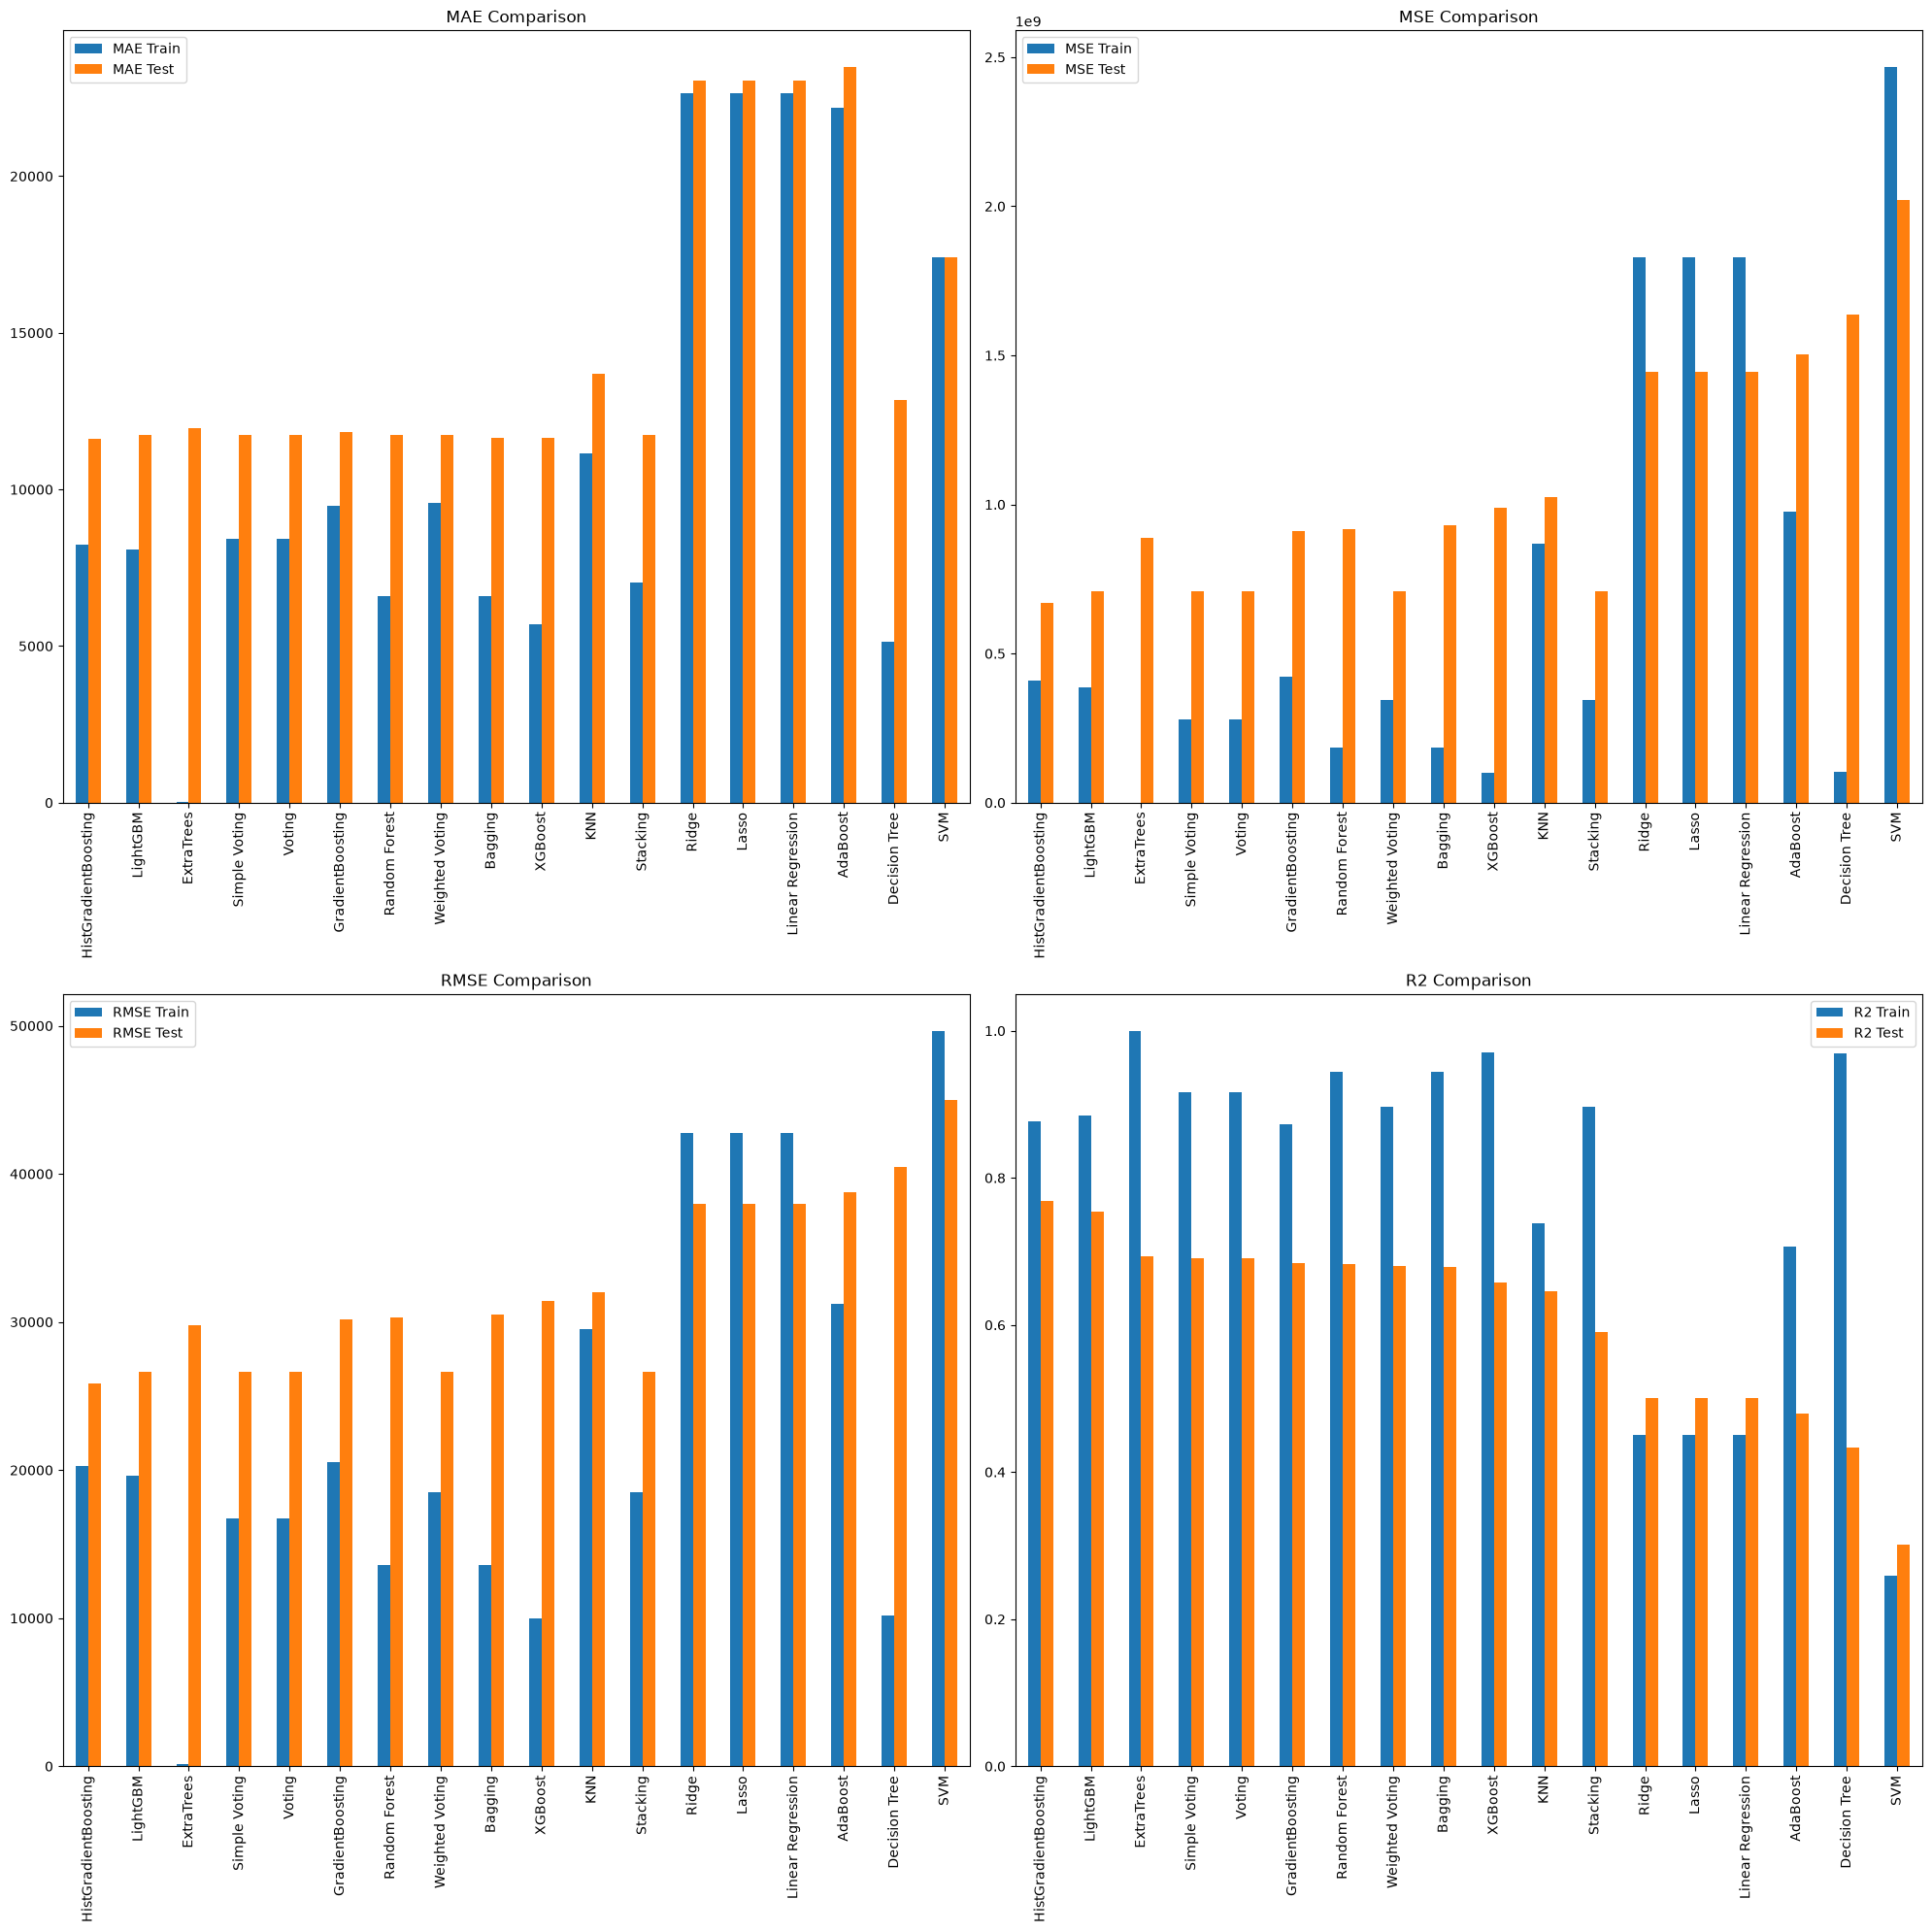

In [100]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()